# Baseline

**Objetivo:** criar modelos de referência para saber quanto cada etapa realmente acrescenta antes de avaliar modelos. 

**Entrada:** `data/processado/features_modelo.csv`  
**Saída:** `data/processado/metricas_baseline.csv`

**Reprodutibilidade:** a semente `SEED = 42` fica em `scripts/modelagem.py` e é usada no K-Fold embaralhado. O GroupKFold e o holdout temporal não têm aleatoriedade, então são sempre iguais.

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modelagem import SEED, ALVO, COLUNAS_COMPLETO, COLUNAS_PERFIL, avaliar_modelos, construir_modelos

df = pd.read_csv("../data/processado/features_modelo.csv")

np.random.seed(SEED)
print("SEED:", SEED)

SEED: 42


## Modelos de referência

- **Nível 1, ingênuo:** mediana (e média) global do log do valor. É o piso, mostra se o modelo aprende alguma coisa.
- **Nível 2, regra de domínio:** mediana por posição e por posição + faixa de idade. Mostra até onde o perfil chega sem machine learning.
- **Nível 3, modelo simples:** Ridge só com perfil (idade, idade², posição, estrangeiro). Mostra o que um modelo linear extrai só do perfil.
- **Referência:** Ridge com todas as variáveis. Mostra quanto o desempenho em campo e o contrato acrescentam.

Todos os modelos passam pelas mesmas validações:

- **`kfold_5_aleatorio`:** referência otimista. Mistura temporadas do mesmo jogador entre treino e teste.
- **`groupkfold_5`:** validação principal. Todas as linhas de um jogador ficam do mesmo lado.
- **`holdout_temporal`:** treina na temporada completa (2024) e testa na incompleta (2025).


In [2]:
modelos = construir_modelos()
resultados = avaliar_modelos(df, modelos)
resultados.to_csv("../data/processado/metricas_baseline.csv", index=False)
resultados.round(3)

,validacao,nivel,modelo,n_avaliado,MAE_eur,RMSE_eur,R2_log,MAE_log
0,kfold_5_aleatorio,1 - ingenuo,mediana_global,475,3327052.632,5016064.981,-0.017,0.974
1,groupkfold_5,1 - ingenuo,mediana_global,475,3327052.632,5016064.981,-0.017,0.974
2,holdout_temporal,1 - ingenuo,mediana_global,164,4077743.902,6047190.564,-0.007,1.109
3,kfold_5_aleatorio,1 - ingenuo,media_global,475,3355276.191,5179919.988,-0.007,0.984
4,groupkfold_5,1 - ingenuo,media_global,475,3346550.347,5171316.632,-0.002,0.981
5,holdout_temporal,1 - ingenuo,media_global,164,4123852.292,6255375.139,-0.003,1.126
6,kfold_5_aleatorio,2 - regra de dominio,mediana_posicao,475,3335947.547,4983499.710,0.015,0.973
7,groupkfold_5,2 - regra de dominio,mediana_posicao,475,3328590.233,4946351.194,0.014,0.977
8,holdout_temporal,2 - regra de dominio,mediana_posicao,164,4026094.531,6103596.621,0.063,1.088
9,kfold_5_aleatorio,2 - regra de dominio,mediana_posicao_idade,475,2934238.328,4550745.504,0.331,0.794


## Comparação

O ganho de cada modelo é medido contra o piso (mediana global): quanto o MAE em euros diminuiu e quanto o R² (em log) subiu.

In [3]:
ordem = list(modelos)

def tabela(validacao):
    t = resultados[resultados["validacao"] == validacao].set_index("modelo").loc[ordem]
    piso = t.loc["mediana_global"]
    out = pd.DataFrame({
        "nivel": t["nivel"],
        "MAE_eur": t["MAE_eur"].round(0),
        "R2_log": t["R2_log"].round(3),
        "reducao_MAE_vs_piso": ((1 - t["MAE_eur"] / piso["MAE_eur"]) * 100).round(1).astype(str) + "%",
    })
    return out

print("GroupKFold por jogador")
display(tabela("groupkfold_5"))
print("Holdout temporal (treino 2024, teste 2025)")
display(tabela("holdout_temporal"))

GroupKFold por jogador


,nivel,MAE_eur,R2_log,reducao_MAE_vs_piso
modelo,,,,
mediana_global,1 - ingenuo,3327053.0,-0.017,0.0%
media_global,1 - ingenuo,3346550.0,-0.002,-0.6%
mediana_posicao,2 - regra de dominio,3328590.0,0.014,-0.0%
mediana_posicao_idade,2 - regra de dominio,2949224.0,0.305,11.4%
ridge_perfil,3 - modelo simples,2810739.0,0.425,15.5%
ridge_completo,referencia,2503123.0,0.528,24.8%


Holdout temporal (treino 2024, teste 2025)


,nivel,MAE_eur,R2_log,reducao_MAE_vs_piso
modelo,,,,
mediana_global,1 - ingenuo,4077744.0,-0.007,0.0%
media_global,1 - ingenuo,4123852.0,-0.003,-1.1%
mediana_posicao,2 - regra de dominio,4026095.0,0.063,1.3%
mediana_posicao_idade,2 - regra de dominio,3416373.0,0.443,16.2%
ridge_perfil,3 - modelo simples,3339096.0,0.495,18.1%
ridge_completo,referencia,2967454.0,0.615,27.2%


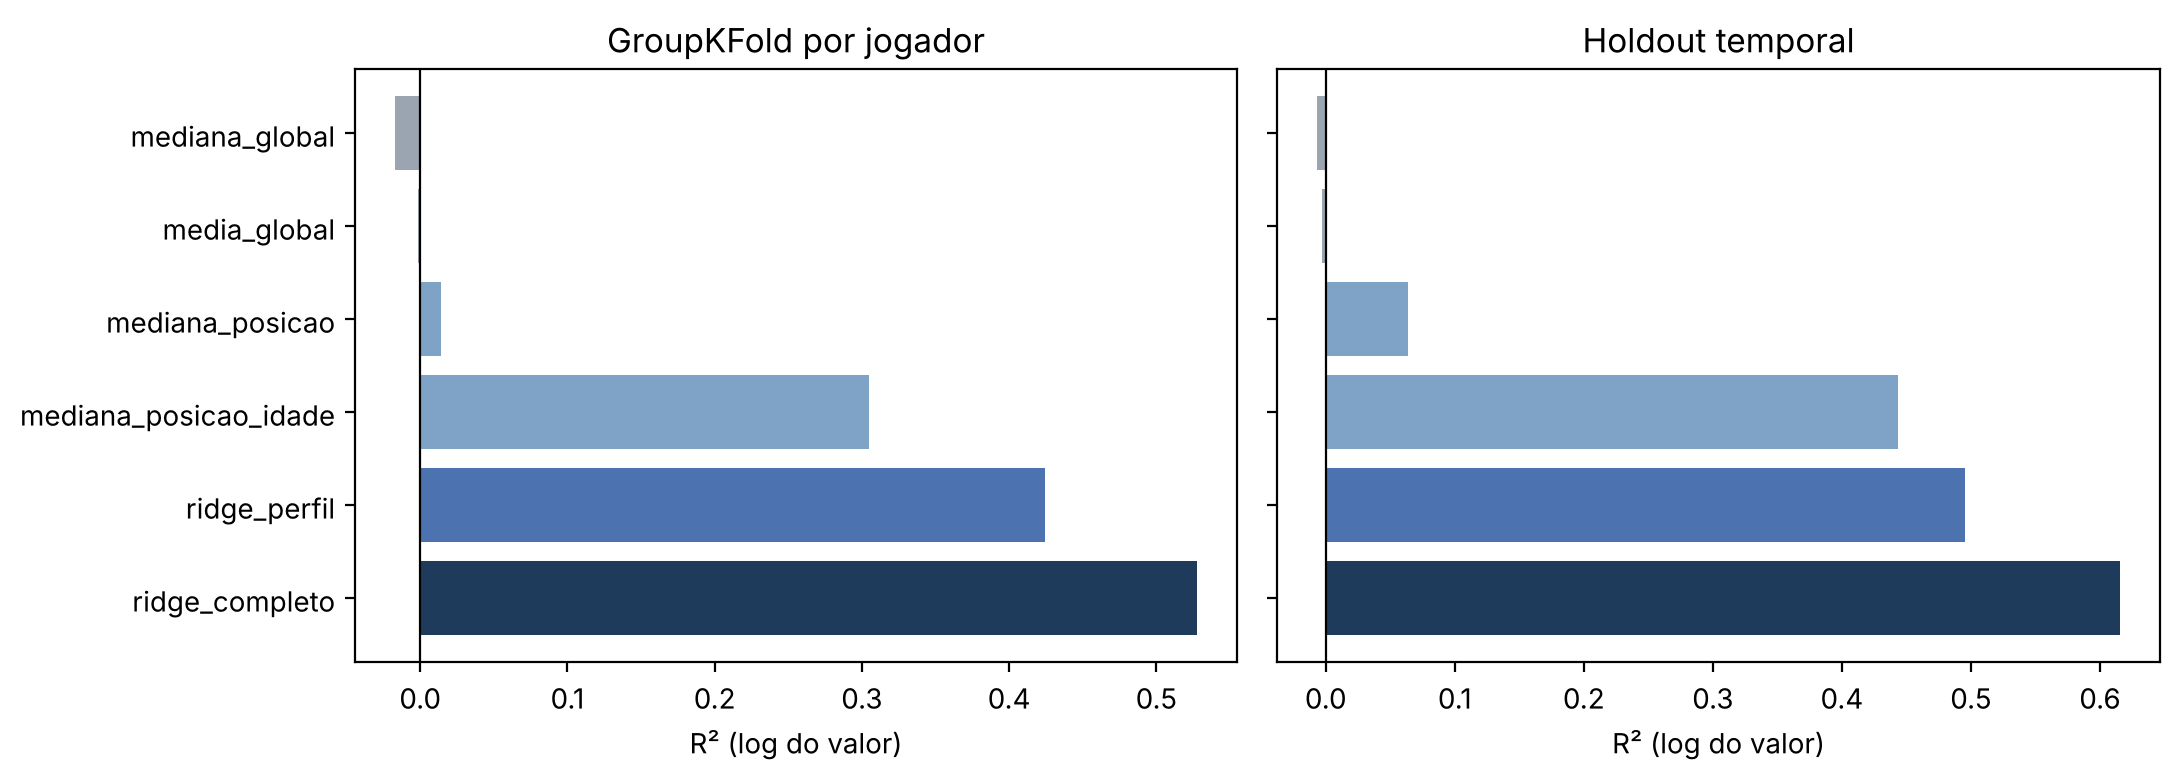

In [4]:
cores = {"1 - ingenuo": "#9AA5B1", "2 - regra de dominio": "#7FA3C7", "3 - modelo simples": "#4C72B0", "referencia": "#1F3B5C"}

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eixo, validacao, titulo in [(eixos[0], "groupkfold_5", "GroupKFold por jogador"), (eixos[1], "holdout_temporal", "Holdout temporal")]:
    t = resultados[resultados["validacao"] == validacao].set_index("modelo").loc[ordem]
    eixo.barh(t.index[::-1], t["R2_log"][::-1], color=[cores[n] for n in t["nivel"][::-1]])
    eixo.axvline(0, color="black", linewidth=0.8)
    eixo.set_title(titulo)
    eixo.set_xlabel("R² (log do valor)")
plt.tight_layout()

fig.savefig("../figuras/baseline_comparacao_r2.png")

- Só a posição não prevê o valor: R² perto de 0.
- A idade é o fator que mais explica o valor.
- O Ridge completo é o melhor (R² de cerca de 0,51 no GroupKFold), mas metade da variação continua sem explicação.


- Só a posição não prevê o valor: R² perto de 0.
- A idade é o fator que mais explica o valor.
- O Ridge completo é o melhor (R² de cerca de 0,51 no GroupKFold), mas metade da variação continua sem explicação.
